# Fase 0 · Etapa 0.4 — Matriz de amortecimento (C2, C4)

> **Base de dados usada:** nenhum dado experimental. Só as **matrizes K e M do próprio
> legado** (propriedades de `material_prop`, malha de 6 nós, engaste-livre) e um
> **caso sintético** com ζ prescrito. Nenhuma base externa.

**Pergunta.** Quando o legado recebe `zetas = [ζ₁, …, ζ₆]`, o modelo resultante tem
mesmo razões de amortecimento ζ₁…ζ₆?

**Teoria (Ewins, cap. 2).** Com Φ normalizado pela massa (ΦᵀMΦ = I), o amortecimento
viscoso modal correto é

$$C = M\,\Phi\,\mathrm{diag}(2\zeta_r\omega_r)\,\Phi^T M \quad\Rightarrow\quad \Phi^T C\,\Phi = \mathrm{diag}(2\zeta_r\omega_r).$$

O legado usa `C = Φ diag(ζ) Φᵀ`: faltam as duas matrizes M e o fator 2ω_r.

**Como medir o ζ que o modelo realmente tem.** Projeção em cada modo não amortecido:
ζ_r = φ_rᵀ C φ_r / (2ω_r) (exato para amortecimento proporcional; estimativa de 1ª
ordem para o resto). ζ_r > 1 significa modo **superamortecido** (não oscila mais). Como
conferência independente, conto quantos autovalores do espaço de estados ficaram reais
(cada modo superamortecido gera 2). Ambas as funções estão testadas em `tests/unit`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.linalg as sla

from dampid.audit import legacy_harness as lh
from dampid.audit import reference as ref

B = lh.load_legacy()


def legacy_system(material, cc="engastado_livre", n_points=6):
    K, M = lh.assemble_legacy(B, material, n_points)
    _, free, _, _ = B.contorno(cc, 6, n_points)
    return K[np.ix_(free, free)], M[np.ix_(free, free)]


def legacy_C(K, M, zetas):
    """Exatamente as linhas de calculo_numerico_modal / frf_direta_modal."""
    _, phi = sla.eigh(K, M, subset_by_index=[0, len(zetas) - 1])
    return (phi @ np.diag(zetas)) @ phi.T


K, M = legacy_system("aluminio")
_, Phi6 = sla.eigh(K, M, subset_by_index=[0, 5])
print("ΦᵀMΦ = I ?", np.allclose(Phi6.T @ M @ Phi6, np.eye(6)))
print("ΦᵀΦ  = I ?", np.allclose(Phi6.T @ Phi6, np.eye(6)), "→ diag(ΦᵀΦ) =", np.round(np.diag(Phi6.T @ Phi6)))

ΦᵀMΦ = I ? True
ΦᵀΦ  = I ? False → diag(ΦᵀΦ) = [  3173.  23947.   3172.  58298. 106193. 114704.]


Com Φ normalizado pela massa, ΦᵀΦ **não** é a identidade — seus termos são da ordem de
1/massa (aqui, milhares). É isso que transforma `Φ diag(ζ) Φᵀ` num amortecimento
enorme.

## 1. C2 — ζ que o modelo legado realmente tem

In [2]:
rows = []
for mat in ["aluminio", "aco", "acrilico"]:
    Km, Mm = legacy_system(mat)
    for zin in (1e-6, 1e-4, 1e-2):
        w, z, n_real = ref.projected_modal_damping(Km, Mm, legacy_C(Km, Mm, [zin] * 6), n_modes=6)
        rows.append({"material": mat, "ζ de entrada": f"{zin:g}",
                     "f₁…f₄ [Hz]": " / ".join(f"{x / 2 / np.pi:.0f}" for x in w[:4]),
                     **{f"ζ modo {i + 1}": f"{z[i]:.2g}" for i in range(4)},
                     "modos superamort.": n_real // 2})
tab = pd.DataFrame(rows)
with pd.option_context("display.width", 200):
    print(tab.to_string(index=False))

Kc, Mc = K, M
w2, Phi = sla.eigh(Kc, Mc, subset_by_index=[0, 5])
C_ok = ref.modal_damping_matrix(Mc, Phi, np.sqrt(w2), np.full(6, 0.01))
_, z_ok, n_ok = ref.projected_modal_damping(Kc, Mc, C_ok, n_modes=6)
print("\nConstrução correta, alumínio, ζ = 1 %:", np.round(z_ok, 6), "| superamortecidos:", n_ok // 2)

material ζ de entrada           f₁…f₄ [Hz] ζ modo 1 ζ modo 2 ζ modo 3 ζ modo 4  modos superamort.
aluminio        1e-06 36 / 223 / 574 / 627     0.37     0.82   0.0014     0.84                  1
aluminio       0.0001 36 / 223 / 574 / 627       37       82     0.14       84                  5
aluminio         0.01 36 / 223 / 574 / 627  3.7e+03  8.2e+03       14  8.4e+03                  6
     aco        1e-06 31 / 191 / 515 / 538    0.041     0.09  0.00015    0.092                  1
     aco       0.0001 31 / 191 / 515 / 538      4.1        9    0.015      9.2                  4
     aco         0.01 31 / 191 / 515 / 538  4.1e+02    9e+02      1.5  9.2e+02                  6
acrilico        1e-06 17 / 107 / 278 / 300     0.93        2   0.0035      2.1                  3
acrilico       0.0001 17 / 107 / 278 / 300       93    2e+02     0.35  2.1e+02                  6
acrilico         0.01 17 / 107 / 278 / 300  9.3e+03    2e+04       35  2.1e+04                  6

Construção correta,

**Confirmado (C2), e de forma mais grave do que o esperado.** O ζ de entrada do legado
é **amplificado por um fator da ordem de 10⁵ a 10⁶**, diferente por modo e por material:

* entrada ζ = 10⁻⁶ ⇒ ζ real de **0,04 a 3** (alumínio: 0,4 no 1º modo, 0,8 no 2º);
* entrada ζ = 10⁻² (1 %) ⇒ ζ real de centenas a dezenas de milhares — o modelo está
  totalmente **superamortecido**.

A construção correta devolve exatamente 1 %. Isso explica de uma vez: (i) por que os
"ζ ótimos" da monografia eram ~10⁻⁶ (é a faixa em que o modelo legado ainda oscila);
(ii) a frase "1 % ζ = 10⁻⁶"; e (iii) a conclusão de que "o modelo superestima o
amortecimento" — um ζ_legado de 10⁻⁶ já é um amortecimento físico de dezenas de por
cento, várias ordens acima do que se espera de uma barra de alumínio (H3: 10⁻⁴–10⁻²).
Também traduz o notebook 02: o ótimo da RVAC em ζ_legado ≈ 10⁻⁴ (acrílico) é um modelo
com dezenas a centenas de vezes o amortecimento crítico.

O 3º modo (o primeiro de flexão no plano, ≈ 574 Hz no Al) é quase poupado porque seus
deslocamentos têm norma euclidiana pequena — mais um sinal de que o fator não é uma
constante que se possa "descontar".

## 2. C4 — modos além do sexto ficam sem amortecimento

max |ζ| nos modos 7–30: legado = 8.8e+00 | correto = 2.2e-19


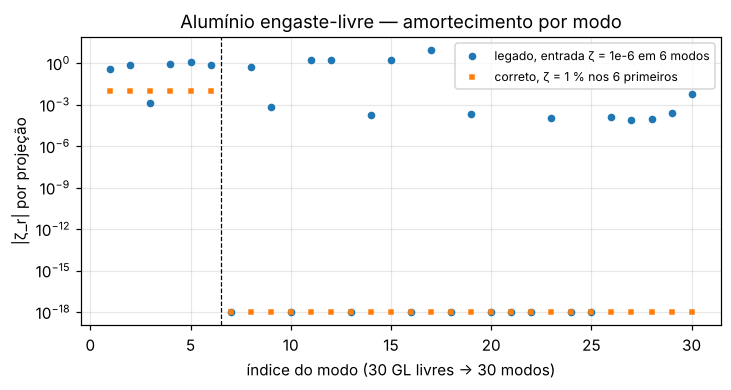

In [3]:
w_all, z_all, _ = ref.projected_modal_damping(Kc, Mc, legacy_C(Kc, Mc, [1e-6] * 6))
_, z_all_ok, _ = ref.projected_modal_damping(Kc, Mc, C_ok)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
idx = np.arange(1, len(z_all) + 1)
ax.semilogy(idx, np.maximum(np.abs(z_all), 1e-18), "o", ms=4, label="legado, entrada ζ = 1e-6 em 6 modos")
ax.semilogy(idx, np.maximum(np.abs(z_all_ok), 1e-18), "s", ms=3, label="correto, ζ = 1 % nos 6 primeiros")
ax.axvline(6.5, color="k", lw=0.8, ls="--")
ax.set(xlabel="índice do modo (30 GL livres → 30 modos)", ylabel="|ζ_r| por projeção",
       title="Alumínio engaste-livre — amortecimento por modo")
ax.grid(alpha=0.3); ax.legend(fontsize=8)
print("max |ζ| nos modos 7–30: legado =", f"{np.abs(z_all[6:]).max():.1e}", "| correto =", f"{np.abs(z_all_ok[6:]).max():.1e}")

**Parcialmente confirmado (C4) — o problema é outro.** A hipótese herdada era "modos
além do 5º/6º recebem amortecimento **zero**". A evidência mostra que, no legado, eles
recebem amortecimento **descontrolado**: como `Φ diag(ζ) Φᵀ` não é diagonal na base
modal, o amortecimento "vaza" para os modos 7–30, com ζ por projeção de ~0 até ≈ 9
(superamortecidos) — sem relação com nada que o usuário escolheu. Na construção
correta eles ficam com ζ = 0 exatamente, o que também precisa de tratamento (termos
residuais para modos fora da banda, Fase 7). Conclusão prática igual: os modos fora
da lista têm amortecimento que ninguém controla.

Nota: `calculo_numerico_modal` também faz `if numero_de_modos > 5: numero_de_modos = 5`,
mas essa variável não é usada depois — o número de modos amortecidos é `len(zetas)`.

## Resumo da etapa
| Item | Status | Evidência |
|---|---|---|
| C2 | **confirmado (grave)** | fator de amplificação ~10⁵–10⁶, variável por modo; ζ_legado = 1e-6 ⇒ ζ real 0,04–3; 1e-2 ⇒ modelo superamortecido; construção correta recupera 1 % |
| C4 | **parcial** (reformulado) | modos 7–30 não ficam com ζ = 0: recebem ζ descontrolado (≈0 a 9) por vazamento |